In [88]:
!pip install langchain langchain_core langgraph -qqq

### **Batsman data workflow**

In [89]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [90]:
class BatsmanState(TypedDict):

    runs: int
    balls: int
    fours: int
    sixes: int

    sr: float
    bpb: float
    boundary_percent: float
    summary: str

In [91]:
def calculate_sr(state: BatsmanState):

    sr = (state['runs']/state['balls'])*100

    return {'sr': sr}

In [92]:
def calculate_bpb(state: BatsmanState):

    bpb = state['balls']/(state['fours'] + state['sixes'])

    return {'bpb': bpb}

In [93]:
def calculate_boundary_percent(state: BatsmanState):

    boundary_percent = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs'])*100

    return {'boundary_percent': boundary_percent}

In [94]:
def summary(state: BatsmanState):

    summary = f"""
Strike Rate - {state['sr']} \n
Balls per boundary - {state['bpb']} \n
Boundary percent - {state['boundary_percent']}
"""

    return {'summary': summary}

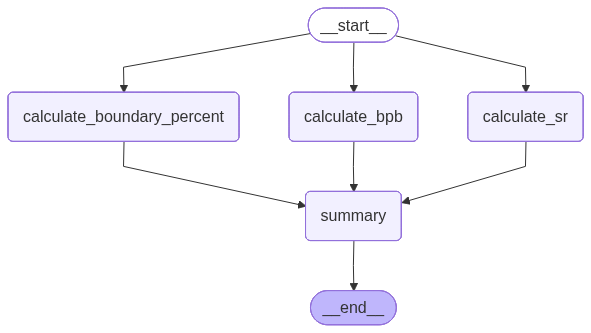

In [95]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_sr', calculate_sr)
graph.add_node('calculate_bpb', calculate_bpb)
graph.add_node('calculate_boundary_percent', calculate_boundary_percent)
graph.add_node('summary', summary)

# edges

graph.add_edge(START, 'calculate_sr')
graph.add_edge(START, 'calculate_bpb')
graph.add_edge(START, 'calculate_boundary_percent')

graph.add_edge('calculate_sr', 'summary')
graph.add_edge('calculate_bpb', 'summary')
graph.add_edge('calculate_boundary_percent', 'summary')

graph.add_edge('summary', END)

workflow = graph.compile()

In [96]:
intial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

workflow.invoke(intial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\nStrike Rate - 200.0 \n\nBalls per boundary - 5.0 \n\nBoundary percent - 48.0\n'}

### **UPSC essayworkflow -structured output**

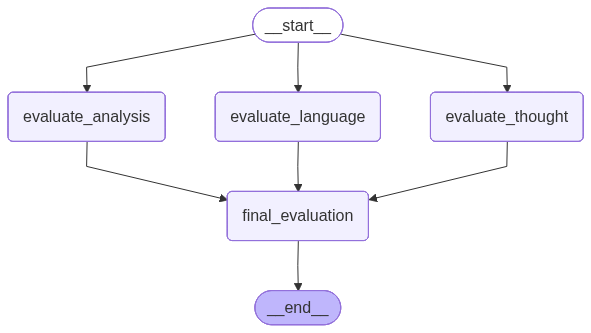

In [97]:
!pip install langchain_openai -qqq

In [98]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated #for reducer fn
import operator #for reducer fn
from langchain_openai import ChatOpenAI
from pydantic import BaseModel,Field #for structured op

In [99]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [100]:
llm=ChatOpenAI(model="gpt-5-nano")

In [101]:
from pydantic import BaseModel,Field
class evaluation_schema(BaseModel):
  feedback:str = Field(description="Detailed feedback for essay")
  score:int =Field(description="score out of 10",ge=0, le=10)

In [102]:
structured_llm=llm.with_structured_output(evaluation_schema)

In [103]:
essay = """India in the Age of AI
As the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.

India's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for All) with a focus on inclusive growth, aiming to leverage AI in healthcare, agriculture, education, and smart mobility.

One of the most promising applications of AI in India lies in agriculture, where predictive analytics can guide farmers on optimal sowing times, weather forecasts, and pest control. In healthcare, AI-powered diagnostics can help address India’s doctor-patient ratio crisis, particularly in rural areas. Educational platforms are increasingly using AI to personalize learning paths, while smart governance tools are helping improve public service delivery and fraud detection.

However, the path to AI-led growth is riddled with challenges. Chief among them is the digital divide. While metropolitan cities may embrace AI-driven solutions, rural India continues to struggle with basic internet access and digital literacy. The risk of job displacement due to automation also looms large, especially for low-skilled workers. Without effective skilling and re-skilling programs, AI could exacerbate existing socio-economic inequalities.

Another pressing concern is data privacy and ethics. As AI systems rely heavily on vast datasets, ensuring that personal data is used transparently and responsibly becomes vital. India is still shaping its data protection laws, and in the absence of a strong regulatory framework, AI systems may risk misuse or bias.

To harness AI responsibly, India must adopt a multi-stakeholder approach involving the government, academia, industry, and civil society. Policies should promote open datasets, encourage responsible innovation, and ensure ethical AI practices. There is also a need for international collaboration, particularly with countries leading in AI research, to gain strategic advantage and ensure interoperability in global systems.

India’s demographic dividend, when paired with responsible AI adoption, can unlock massive economic growth, improve governance, and uplift marginalized communities. But this vision will only materialize if AI is seen not merely as a tool for automation, but as an enabler of human-centered development.

In conclusion, India in the age of AI is a story in the making — one of opportunity, responsibility, and transformation. The decisions we make today will not just determine India’s AI trajectory, but also its future as an inclusive, equitable, and innovation-driven society."""

In [87]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
response=structured_llm.invoke(prompt)
print("feedback",response.feedback)
print("score",response.score)

feedback Overall, the essay demonstrates a strong command of language and a clear, well-structured argument. Strengths include a balanced treatment of opportunities and challenges, concrete examples (agriculture, healthcare, education), and a policy-minded, reader-friendly tone. The prose is fluent with precise diction, effective transitions, and solid use of parallel structures in lists (healthcare, agriculture, education, and smart mobility). The conclusion ties the topic to broader societal goals in a convincing way. 

Areas for improvement: a few sentences are lengthy and could be split to improve readability; there is a touch of repetition (notably the broader framing around the AI era) that could be tightened for conciseness. Consider tightening the opening and some clausal phrases to reduce cognitive load on the reader. Aim for slightly more varied sentence length to maintain rhythm, and ensure perpetual consistency in punctuation style (the dash is fine, but standardization acr

In [104]:
from typing import TypedDict, Annotated
import operator

class UPSCstate(TypedDict):
  essay: str
  language_feedback: str
  analysis_feedback: str
  clarity_feedback: str
  overall_feedback: str
  individual_scores: Annotated[list[int], operator.add] #we are using reducer function here for concatatnation of scores
  avg_score: float

In [105]:
def evaluate_language(state: UPSCstate):

    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_llm.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}

def evaluate_analysis(state: UPSCstate):

    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_llm.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}

def evaluate_thought(state: UPSCstate):

    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_llm.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}

def final_evaluation(state: UPSCstate):

    # summary feedback
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = llm.invoke(prompt).content

    # avg calculate
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}



In [106]:
graph = StateGraph(UPSCstate)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()

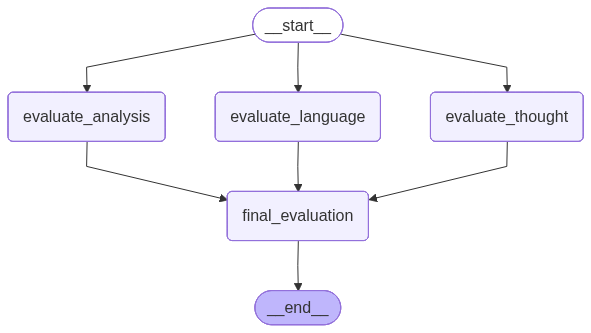

In [107]:
workflow

In [109]:
intial_state = {
    'essay': essay
}

workflow.invoke(intial_state)

{'essay': "India in the Age of AI\nAs the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.\n\nIndia's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for 

````markdown
# LangGraph Parallel Execution — Maintaining Order of Scores

## Problem
- Nodes (`evaluate_language`, `evaluate_analysis`, `evaluate_thought`) run **in parallel**
- Using reducer:
  ```python
  individual_scores: Annotated[list[int], operator.add]
````

* `operator.add` concatenates results in **arrival order**
* Arrival order is **non-deterministic** → sequence breaks

---

## ❌ Why reducer ordering is unsafe

* Parallel nodes finish at different times
* Reducers are **commutative**, not sequential
* Cannot guarantee positional meaning in lists

---

## ✅ Recommended Solution (Deterministic & Parallel-safe)

### Use structured state instead of list reducer

```python
from typing_extensions import TypedDict
from typing import Dict

class UPSCstate(TypedDict):
    individual_scores: Dict[str, int]
```

---

### Each node writes to a fixed key

```python
def evaluate_language(state):
    return {"individual_scores": {"language": 7}}

def evaluate_analysis(state):
    return {"individual_scores": {"analysis": 8}}

def evaluate_thought(state):
    return {"individual_scores": {"thought": 6}}
```

* Dict merging is safe in parallel
* No reducer required

---

### Enforce order in final node

```python
def final_evaluation(state):
    ordered_scores = [
        state["individual_scores"]["language"],
        state["individual_scores"]["analysis"],
        state["individual_scores"]["thought"],
    ]
    return {"final_score": sum(ordered_scores)}
```

---

## ✅ Result

* Parallel execution preserved
* Score order guaranteed
* Clean, readable, LangGraph-native

---

## Summary

| Approach              | Parallel Safe | Order Safe      |
| --------------------- | ------------- | --------------- |
| `list + operator.add` | ✅             | ❌               |
| `dict[key → score]`   | ✅             | ✅ (Recommended) |

```
```
